Lab 6: Shuvam Chowdhury

## A/B Testing, Randomized Controlled Trials

- We want to estimate the **average treatment effect**: The average difference in outcomes between the treatment and control groups
- Remember, the stakes are something like: If we implement this intervention at the scale of millions of patients, how many lives are:
    - Saved because the treatment works and our experiment showed it did (Good)
    - Not lost because the treatment doesn't work and our experiment showed it doesn't work (Good)
    - Not saved because the treatment works but our experiment failed to show it did (Bad)
    - Lost because the treatment actually harms patients, but our experiment falsely suggested it works (Very bad)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

We generally can't compare what would have happened to observation $i$, if they had been assigned to the other treatment. This means we only observe
$$
y_{iA} = \text{Outcome for $i$ receiving treatment $A$ }
$$
or
$$
y_{iB} = \text{Outcome for $i$ receiving treatment $B$ }
$$
but not both. The **average outcome** for group $A$ is
$$
\frac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA}
$$
and the **average outcome** for group $B$ is
$$
\frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}.
$$
When we difference them, we get the **Average Treatment Effect (ATE)**:
$$
ATE = \dfrac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA} \quad - \quad \frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}
$$
As long as treatment is randomly assigned, there is no reason to think that the participants in group $A$ or $B$ are systematically different, and the **ATE** is an unbiased estimator of the true contrast in outcomes between groups $B$ and $A$. We "average away" the differences across the two groups to get an estimate of the difference in outcomes.

We then use bootstrapping to do two things:

1. Estimate the density/distribution for the averages outcomes in both groups
2. Estimate the ATE and its density/distribution

## Part 1

- First, we're going to evaluate a particular clinical trial, on chronic kidney disease:
    - ISCHEMIA-Chronic Kidney Disease Trial (ISCHEMIA-CKD)
    - ClinicalTrials.gov ID NCT01985360
    - Sponsor NYU Langone Health
    - Information provided by NYU Langone Health (Responsible Party)
- The study compared a "routine invasive therapy" (intra-aortic balloon pumps) intended to reduce death/heart attack versus more conservative medical interventions during heart surgery

<div>
<img src="./src/ischemia.png" width="700"/>
</div>

**1.** Load the `./data/iabp.csv` data. Cross tabulate `Group` and `Survived`. What is the point estimate of the ATE? Would you rather get the intra aortic balloon pump or not? Remember, **Invasive** means pump and **Conservative** means not.

In [2]:
df = pd.read_csv('./data/iabp.csv')

## Crosstabs, average treatment effect:
print(pd.crosstab( df['Group'], df['Survived']), '\n')

ate = df.loc[ df['Group'] == 'Invasive', 'Survived'].mean() \
    - df.loc[ df['Group'] == 'Conservative', 'Survived'].mean() 
print('Estimated ATE: ', np.round(ate, 3))

Survived      0.0  1.0
Group                 
Conservative  291   98
Invasive      294   94 

Estimated ATE:  -0.01


Answer 1: The point estimate of the ATE is -0.01. The survival rate in the Invasive group is about 1 percentage point lower than in the Conservative group. From the crosstab 94 of 388 Invasive patients survived (about 0.242), compared with 98 of 389 Conservative patients (about 0.252). Going by this point estimate alone I would rather not get the intra aortic balloon pump because the Conservative group had a slightly higher survival rate.

**2.** Bootstrap the average outcome for group A, the average outcome for group B, and difference then to get the ATE, 10,000 times. Store all of these estimates. This is important: **Bootstrap the two groups separately, since this is a clinical trial and there was random assignment (we want to maintain the balance across treatment arms because that maximizes statistical power)**.

In [3]:
## Bootstrapping:
R = 10_000

df_a = df.loc[ df['Group'] == 'Invasive',:]
df_b = df.loc[ df['Group'] == 'Conservative',:]

outcome_a = []
outcome_b = []
ate = [] # Store computed effects

for t in range(R):
    ## Resample:
    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)

    ## Evaluate outcomes:
    oat = df_at['Survived'].mean() # Mean outcome for A
    obt = df_bt['Survived'].mean() # Mean outcome for B    

    ## Compute ATE:
    ate_t = oat - obt # Compute ATE for this bootstrap sample
    
    ## Store results:
    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    ate.append(ate_t) # Save new value

**3.** Make a plot of the KDEs of the outcomes for the two groups, and a plot of the ECDFs for the two groups. What relationships do you see between the two groups?

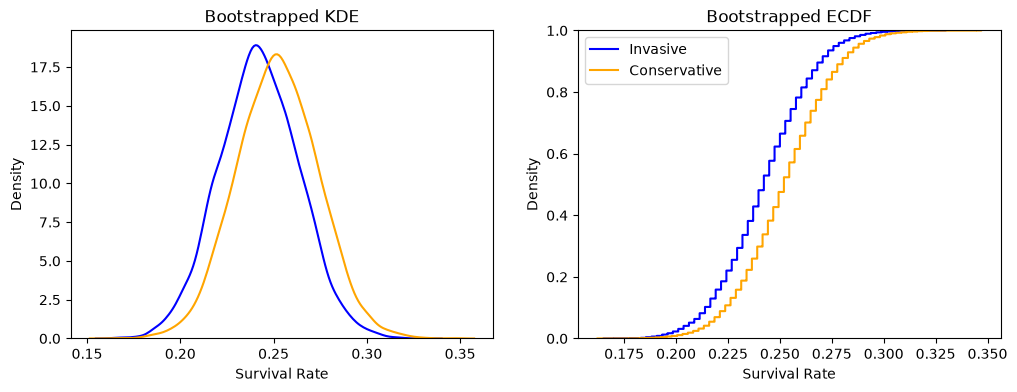

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Invasive', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Conservative', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Invasive', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Conservative', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Density')

plt.legend()
plt.show()

Answer 3: In the Bootstrapped KDE plot, both groups have a roughly bell-shaped distribution of bootstrapped survival rates. The Invasive curve peaks near 0.24 and the Conservative curve peaks near 0.25. The two curves overlap heavily and both run from about 0.18 to about 0.32. In the Bootstrapped ECDF plot the Conservative curve sits slightly to the right of the Invasive curve at every level. That means the Conservative group's bootstrapped survival rates tend to be a little higher. The gap between the two curves is small compared with how much they overlap so the plots suggest only a slight difference in survival between the two groups.

**4.** Make a plot of the KDE and ECDF for the ATE. Does it have a roughly bell shape? What range of values are possible for this intervention?

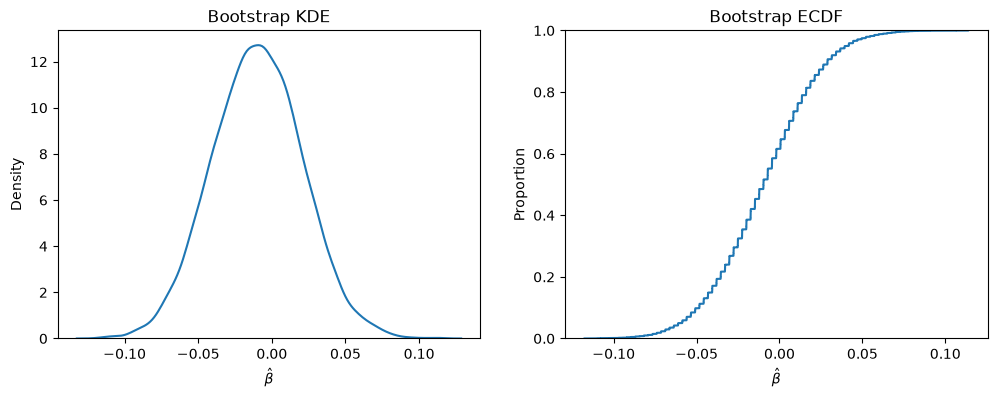

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF
sns.ecdfplot(ate, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")

plt.show()


Answer 4: Yes the bootstrapped ATE has a roughly bell shape. In the Bootstrap KDE plot it is centered near -0.01 and fairly symmetric with similar tails on both sides. In the Bootstrap KDE and Bootstrap ECDF plots the bootstrapped ATE values run from about -0.11 to about 0.11. Most of them fall between about -0.10 and 0.08. This range of possible values includes both negative effects where the Invasive group has lower survival, and positive effects where the Invasive group has higher survival. The range also includes zero.

**5.** Compute 90%, 95%, and 99% confidence intervals for the ATE. Is zero in those intervals? For which do we "fail to reject the null hypothesis that the effect size is zero" and for which do we "reject the null hypothesis that the effect size is zero"?

In [6]:
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.05877382  0.04176086]
95% CI: [-0.06888533  0.04962533]
99% CI: [-0.0869253   0.07017094]


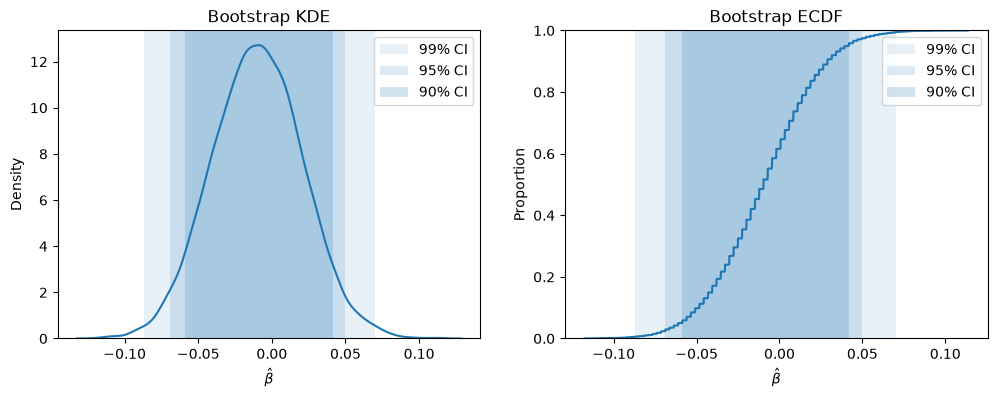

In [7]:
# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

Answer 5: The 90% confidence interval for the ATE is -0.059 to 0.042. The 95% interval is -0.069 to 0.050, and the 99% interval is -0.087 to 0.070. Zero is inside all three intervals. So at the 90%, 95% and 99% levels we fail to reject the null hypothesis that the effect size is zero. There is no level among these three where we reject it.

**6.** What have we learned about inserting balloons into hearts?

Answer 6: We learned that this trial does not show a benefit from the intra aortic balloon pump. The point estimate of the ATE is -0.01 so the survival rate was about 1 percentage point lower in the Invasive group than in the Conservative group. The bootstrapped ATE is centered near -0.01. Its 90%, 95% and 99% confidence intervals all contain zero so we fail to reject the null hypothesis that the effect size is zero. Since the pump is more invasive and showed no survival advantage this trial does not support using it over the conservative approach.

# Part 2

In `./data/diabetes.csv`, there is data from a clinical trial considering three treatments for pre-diabetics to reduce the progression to full diabetes: metformin, rosiglitazone, and lifestyle adjustments (diet, exercise). Unlike Part 1, there aren't two treatment arms (i.e. A = aortic balloon, B = no aortic balloon), but three (met, rosi, lifestyle).

You are a data analyst working for `clinicaltrials.gov` and the FDA to provide an unbiased review of the trial's results. The researchers have provided you with `./data/diabests.csv`.

In an ipynb or py file:

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 
2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 
3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.
4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.
5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

Then:

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 

In [15]:
# Loads data:
df2 = pd.read_csv('./data/diabetes.csv')

# Converts outcome to numeric
df2['success'] = (df2['outcome'] == 'success').astype(int)

# Crosstab of treatment and outcome
print(pd.crosstab(df2['treatment'], df2['outcome']), '\n')

# Average outcome (success rate) for each group
groups = ['met', 'rosi', 'lifestyle']
for group in groups:
    group_mean = df2.loc[df2['treatment'] == group, 'success'].mean() # Mean outcome for this group
    print(group, 'average outcome:', np.round(group_mean, 3))


outcome    failure  success
treatment                  
lifestyle      109      125
met            120      112
rosi            90      143 

met average outcome: 0.483
rosi average outcome: 0.614
lifestyle average outcome: 0.534


Answer 1: From the crosstab the lifestyle group had 125 successes and 109 failures. The met group had 112 successes and 120 failures, and the rosi group had 143 successes and 90 failures. The average outcome is the proportion of patients with a success. It is 0.483 for met, 0.614 for rosi and 0.534 for lifestyle. Rosi has the highest average outcome. Met is the only group with more failures than successes.

2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 


In [16]:
# Bootstrapping:
R = 10_000
rng = np.random.default_rng(5030) # Seeded generator so reruns give the same resamples

# Splits data into the three treatment arms:
df_met = df2.loc[ df2['treatment'] == 'met',:]
df_rosi = df2.loc[ df2['treatment'] == 'rosi',:]
df_life = df2.loc[ df2['treatment'] == 'lifestyle',:]

outcome_met = []  
outcome_rosi = []
outcome_life = [] 

for t in range(R):
    # Resamples within each arm:
    df_met_t = df_met.sample(frac=1.0, replace=True, random_state=rng)
    df_rosi_t = df_rosi.sample(frac=1.0, replace=True, random_state=rng)
    df_life_t = df_life.sample(frac=1.0, replace=True, random_state=rng)

    # Evaluates outcomes:
    o_met_t = df_met_t['success'].mean()   
    o_rosi_t = df_rosi_t['success'].mean() 
    o_life_t = df_life_t['success'].mean() 

    # Stores results:
    outcome_met.append(o_met_t)   
    outcome_rosi.append(o_rosi_t) 
    outcome_life.append(o_life_t) 


3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.

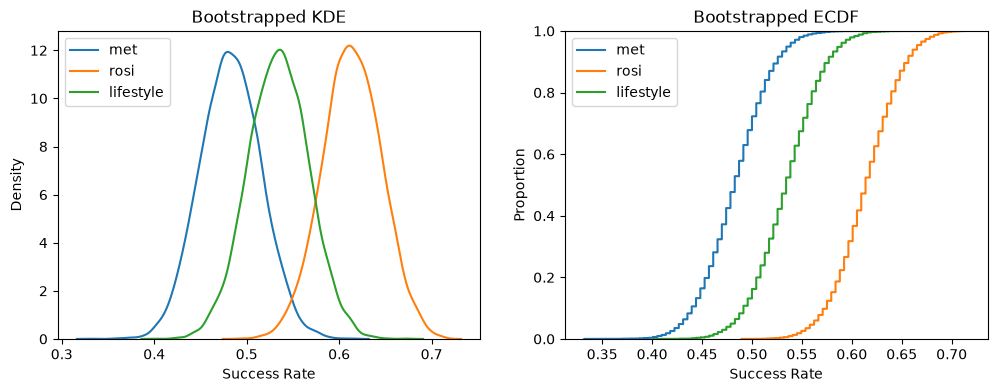

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# KDEs of the bootstrapped outcomes
sns.kdeplot(outcome_met, label='met', ax=ax[0])
sns.kdeplot(outcome_rosi, label='rosi', ax=ax[0])
sns.kdeplot(outcome_life, label='lifestyle', ax=ax[0])
ax[0].set(title='Bootstrapped KDE', xlabel='Success Rate', ylabel='Density')
ax[0].legend()

# ECDFs of the bootstrapped outcomes
sns.ecdfplot(outcome_met, label='met', ax=ax[1])
sns.ecdfplot(outcome_rosi, label='rosi', ax=ax[1])
sns.ecdfplot(outcome_life, label='lifestyle', ax=ax[1])
ax[1].set(title='Bootstrapped ECDF', xlabel='Success Rate', ylabel='Proportion')
ax[1].legend()

plt.show()


Answer 3: In the Bootstrapped KDE plot all three groups have a roughly bell-shaped distribution of bootstrapped success rates with similar spreads. The met curve peaks near 0.48, the lifestyle curve near 0.53 and the rosi curve near 0.61. Met and lifestyle overlap heavily, lifestyle and rosi overlap less, and met and rosi overlap only slightly in their tails. In the Bootstrapped ECDF plot the curves keep the same order at every level. Met is furthest left, lifestyle is in the middle and rosi is furthest right. This means rosi's bootstrapped success rates tend to be the highest and met's the lowest. Rosi's curve is also more clearly separated from the other two than met and lifestyle are from each other.

4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.


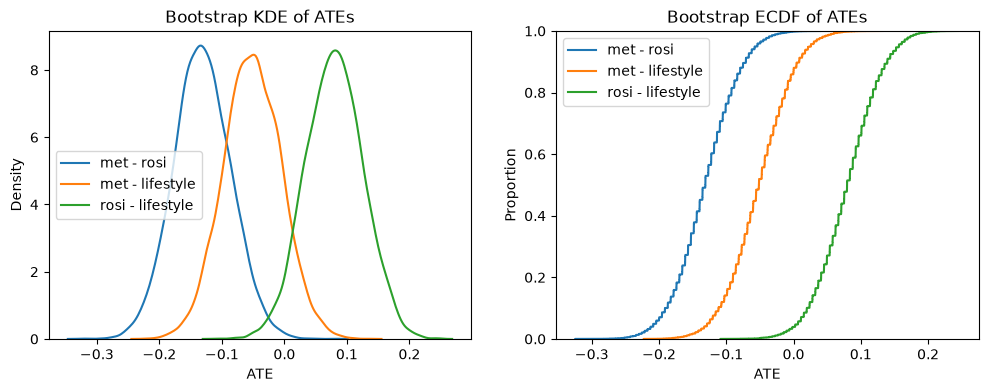

In [18]:
# Computes the three pairwise ATEs for each bootstrap sample
ate_met_rosi = []  # met - rosi
ate_met_life = []  # met - lifestyle
ate_rosi_life = [] # rosi - lifestyle

for t in range(R):
    ate_met_rosi.append(outcome_met[t] - outcome_rosi[t])  
    ate_met_life.append(outcome_met[t] - outcome_life[t])   
    ate_rosi_life.append(outcome_rosi[t] - outcome_life[t]) 

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# KDEs of the pairwise ATEs
sns.kdeplot(ate_met_rosi, label='met - rosi', ax=ax[0])
sns.kdeplot(ate_met_life, label='met - lifestyle', ax=ax[0])
sns.kdeplot(ate_rosi_life, label='rosi - lifestyle', ax=ax[0])
ax[0].set(title='Bootstrap KDE of ATEs', xlabel='ATE', ylabel='Density')
ax[0].legend()

# ECDFs of the pairwise ATEs
sns.ecdfplot(ate_met_rosi, label='met - rosi', ax=ax[1])
sns.ecdfplot(ate_met_life, label='met - lifestyle', ax=ax[1])
sns.ecdfplot(ate_rosi_life, label='rosi - lifestyle', ax=ax[1])
ax[1].set(title='Bootstrap ECDF of ATEs', xlabel='ATE', ylabel='Proportion')
ax[1].legend()

plt.show()


5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

In [19]:
# Percentile bootstrap confidence intervals for met - rosi
ci90_met_rosi = np.quantile(ate_met_rosi, [.05, .95])
ci95_met_rosi = np.quantile(ate_met_rosi, [.025, .975])
ci99_met_rosi = np.quantile(ate_met_rosi, [.005, .995])

# Percentile bootstrap confidence intervals for met - lifestyle
ci90_met_life = np.quantile(ate_met_life, [.05, .95])
ci95_met_life = np.quantile(ate_met_life, [.025, .975])
ci99_met_life = np.quantile(ate_met_life, [.005, .995])

# Percentile bootstrap confidence intervals for rosi - lifestyle
ci90_rosi_life = np.quantile(ate_rosi_life, [.05, .95])
ci95_rosi_life = np.quantile(ate_rosi_life, [.025, .975])
ci99_rosi_life = np.quantile(ate_rosi_life, [.005, .995])

print(f"met - rosi 90% CI: {ci90_met_rosi}")
print(f"met - rosi 95% CI: {ci95_met_rosi}")
print(f"met - rosi 99% CI: {ci99_met_rosi}", '\n')

print(f"met - lifestyle 90% CI: {ci90_met_life}")
print(f"met - lifestyle 95% CI: {ci95_met_life}")
print(f"met - lifestyle 99% CI: {ci99_met_life}", '\n')

print(f"rosi - lifestyle 90% CI: {ci90_rosi_life}")
print(f"rosi - lifestyle 95% CI: {ci95_rosi_life}")
print(f"rosi - lifestyle 99% CI: {ci99_rosi_life}")


met - rosi 90% CI: [-0.20421415 -0.05372207]
met - rosi 95% CI: [-0.22125203 -0.04064304]
met - rosi 99% CI: [-0.2471142  -0.01056312] 

met - lifestyle 90% CI: [-0.12835433  0.02560603]
met - lifestyle 95% CI: [-0.14146865  0.0386835 ]
met - lifestyle 99% CI: [-0.17156646  0.06867098] 

rosi - lifestyle 90% CI: [0.00669455 0.15659734]
rosi - lifestyle 95% CI: [-0.01038159  0.16945453]
rosi - lifestyle 99% CI: [-0.03624399  0.19524238]


Answer 5: For met − rosi the 90% confidence interval is -0.204 to -0.054, the 95% interval is -0.221 to -0.041 and the 99% interval is -0.247 to -0.011. Zero is outside all three intervals. So we reject the null hypothesis that the effect size is zero at every level. Met's success rate is significantly lower than rosi's.

For met − lifestyle the 90% interval is -0.128 to 0.026, the 95% interval is -0.141 to 0.039 and the 99% interval is -0.172 to 0.069. Zero is inside all three so we fail to reject the null hypothesis at every level. There is no significant difference between met and lifestyle.

For rosi − lifestyle the 90% interval is 0.007 to 0.157, so zero is outside it and we reject the null hypothesis at the 90% level. The 95% interval (-0.010 to 0.169) and the 99% interval (-0.036 to 0.195) both contain zero so we fail to reject at those levels. Rosi's advantage over lifestyle is significant only at the 90% level.

Rosi seems the most effective. It had the highest average outcome (0.614), it is significantly better than met at every level and its advantage over lifestyle is significant at the 90% level only.

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

Report attached as PDF "Lab 6 Report"